In [3]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sn

df1 = pd.read_csv(r"C:\Users\Admin\Documents\datasets\House Price Prediction Dataset.csv")
print(df1)


        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0        1  1360         5          4       3       1970  Downtown  Excellent   
1        2  4272         5          4       3       1958  Downtown  Excellent   
2        3  3592         2          2       3       1938  Downtown       Good   
3        4   966         4          2       2       1902  Suburban       Fair   
4        5  4926         1          4       2       1975  Downtown       Fair   
...    ...   ...       ...        ...     ...        ...       ...        ...   
1995  1996  4994         5          4       3       1923  Suburban       Poor   
1996  1997  3046         5          2       1       2019  Suburban       Poor   
1997  1998  1062         5          1       2       1903     Rural       Poor   
1998  1999  4062         3          1       2       1936     Urban  Excellent   
1999  2000  2989         5          1       3       1903  Suburban       Fair   

     Garage   Price  
0    

In [4]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [5]:
df1.describe()


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [6]:
print(len(df1.columns))
print(len(df1.Area))
print(len(df1))

10
2000
2000


In [7]:
print(df1.dtypes)
print("number of missing values:\n", df1.isnull().sum())


Id           int64
Area         int64
Bedrooms     int64
Bathrooms    int64
Floors       int64
YearBuilt    int64
Location       str
Condition      str
Garage         str
Price        int64
dtype: object
number of missing values:
 Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [8]:
print("number of rows before removing duplicates:", df1.count())
df2 = df1.drop_duplicates()
print(df2)
print("number of rows after removing duplicates:", df2.count())

number of rows before removing duplicates: Id           2000
Area         2000
Bedrooms     2000
Bathrooms    2000
Floors       2000
YearBuilt    2000
Location     2000
Condition    2000
Garage       2000
Price        2000
dtype: int64
        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0        1  1360         5          4       3       1970  Downtown  Excellent   
1        2  4272         5          4       3       1958  Downtown  Excellent   
2        3  3592         2          2       3       1938  Downtown       Good   
3        4   966         4          2       2       1902  Suburban       Fair   
4        5  4926         1          4       2       1975  Downtown       Fair   
...    ...   ...       ...        ...     ...        ...       ...        ...   
1995  1996  4994         5          4       3       1923  Suburban       Poor   
1996  1997  3046         5          2       1       2019  Suburban       Poor   
1997  1998  1062         5         

In [9]:
y = df2['Price']
x = df2[['Id' , 'Area' , 'Bedrooms' , 'Bathrooms' , 'Floors' , 'Garage' , 'Condition' , 'Location']]

print(df2.corr(numeric_only=True)["Price"].sort_values(ascending=False))

print(df2.groupby('Price')[x.columns].sum())




Price        1.000000
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Id          -0.025643
Name: Price, dtype: float64
          Id  Area  Bedrooms  Bathrooms  Floors Garage Condition  Location
Price                                                                     
50005   1168  4260         2          2       1    Yes      Fair     Rural
50064    837  2871         4          2       1     No      Poor  Suburban
51082   1729   509         4          1       2     No      Fair     Urban
51845   1593  4368         5          4       2     No      Fair  Downtown
52024   1464  4138         3          4       1     No      Fair     Urban
...      ...   ...       ...        ...     ...    ...       ...       ...
997719   242  2985         4          3       3    Yes      Poor     Urban
998084  1553  2860         2          2       3     No      Fair  Downtown
998128  1007   736         3          2       3    Yes      Good  Do

In [10]:
print(df2.dtypes)
print(df2['Id'].astype(int))
print(df2['Area'].astype(int))
print(df2['Bedrooms'].astype(int))
print(df2['Bathrooms'].astype(int))
print(df2['Floors'].astype(int))
print(df2['Price'].astype(int))





Id           int64
Area         int64
Bedrooms     int64
Bathrooms    int64
Floors       int64
YearBuilt    int64
Location       str
Condition      str
Garage         str
Price        int64
dtype: object
0          1
1          2
2          3
3          4
4          5
        ... 
1995    1996
1996    1997
1997    1998
1998    1999
1999    2000
Name: Id, Length: 2000, dtype: int64
0       1360
1       4272
2       3592
3        966
4       4926
        ... 
1995    4994
1996    3046
1997    1062
1998    4062
1999    2989
Name: Area, Length: 2000, dtype: int64
0       5
1       5
2       2
3       4
4       1
       ..
1995    5
1996    5
1997    5
1998    3
1999    5
Name: Bedrooms, Length: 2000, dtype: int64
0       4
1       4
2       2
3       2
4       4
       ..
1995    4
1996    2
1997    1
1998    1
1999    1
Name: Bathrooms, Length: 2000, dtype: int64
0       3
1       3
2       3
3       2
4       2
       ..
1995    3
1996    1
1997    2
1998    2
1999    3
Name: Floors, Len

In [11]:
df2 = df1.drop_duplicates()
df2 = pd.get_dummies(df2, columns=["Condition", "Location"])
print(df2)

        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt Garage   Price  \
0        1  1360         5          4       3       1970     No  149919   
1        2  4272         5          4       3       1958     No  424998   
2        3  3592         2          2       3       1938     No  266746   
3        4   966         4          2       2       1902    Yes  244020   
4        5  4926         1          4       2       1975    Yes  636056   
...    ...   ...       ...        ...     ...        ...    ...     ...   
1995  1996  4994         5          4       3       1923     No  295620   
1996  1997  3046         5          2       1       2019    Yes  580929   
1997  1998  1062         5          1       2       1903     No  476925   
1998  1999  4062         3          1       2       1936    Yes  161119   
1999  2000  2989         5          1       3       1903     No  482525   

      Condition_Excellent  Condition_Fair  Condition_Good  Condition_Poor  \
0                    T

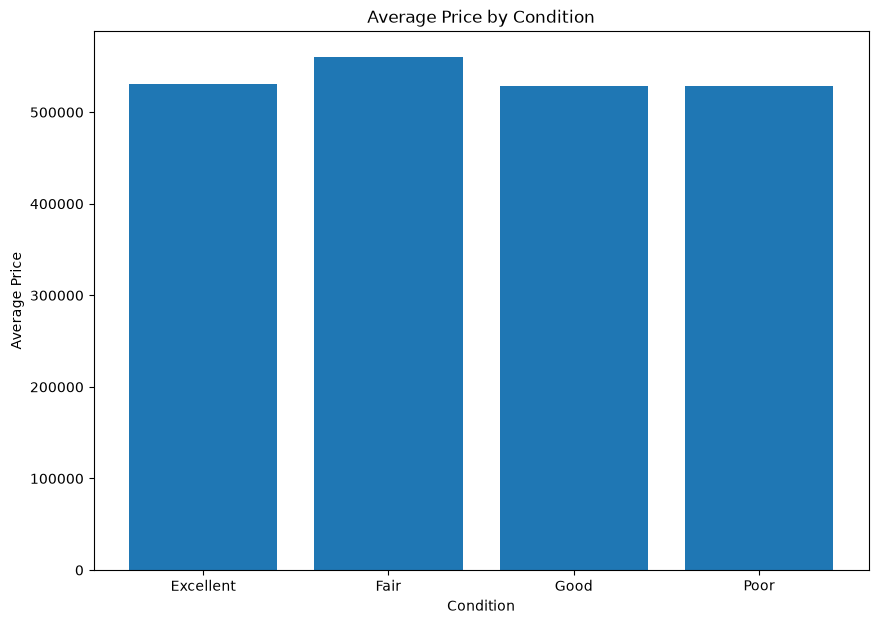

In [12]:
average_price_by_condition = df1.groupby("Condition")["Price"].mean()

plt.figure(figsize=(10, 7))
plt.bar(average_price_by_condition.index, average_price_by_condition.values)
plt.title("Average Price by Condition")
plt.xlabel("Condition")
plt.ylabel("Average Price")
plt.show()

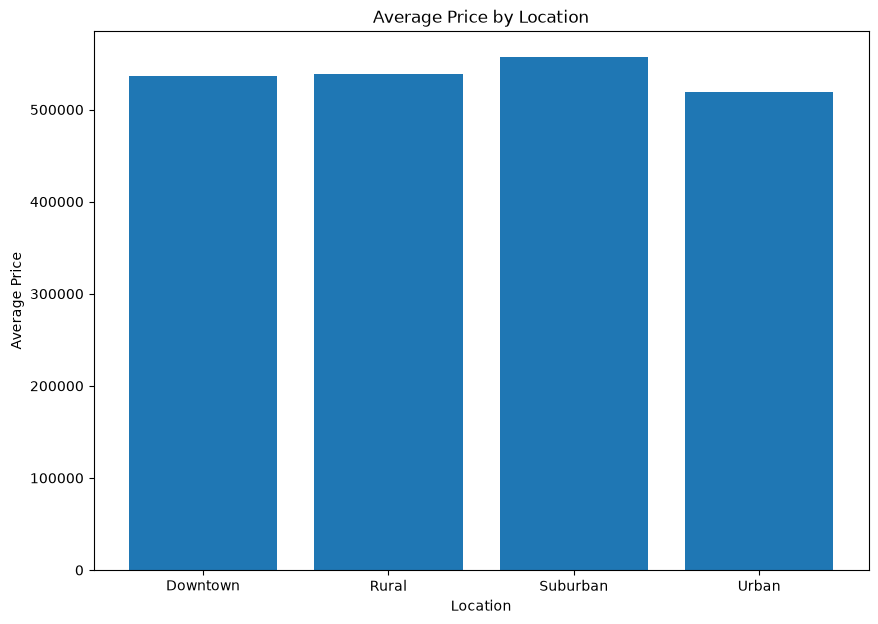

In [13]:
average_price_by_location = df1.groupby("Location")["Price"].mean()

plt.figure(figsize=(10, 7))
plt.bar(average_price_by_location.index, average_price_by_location.values)
plt.title("Average Price by Location")
plt.xlabel("Location")
plt.ylabel("Average Price")
plt.show()

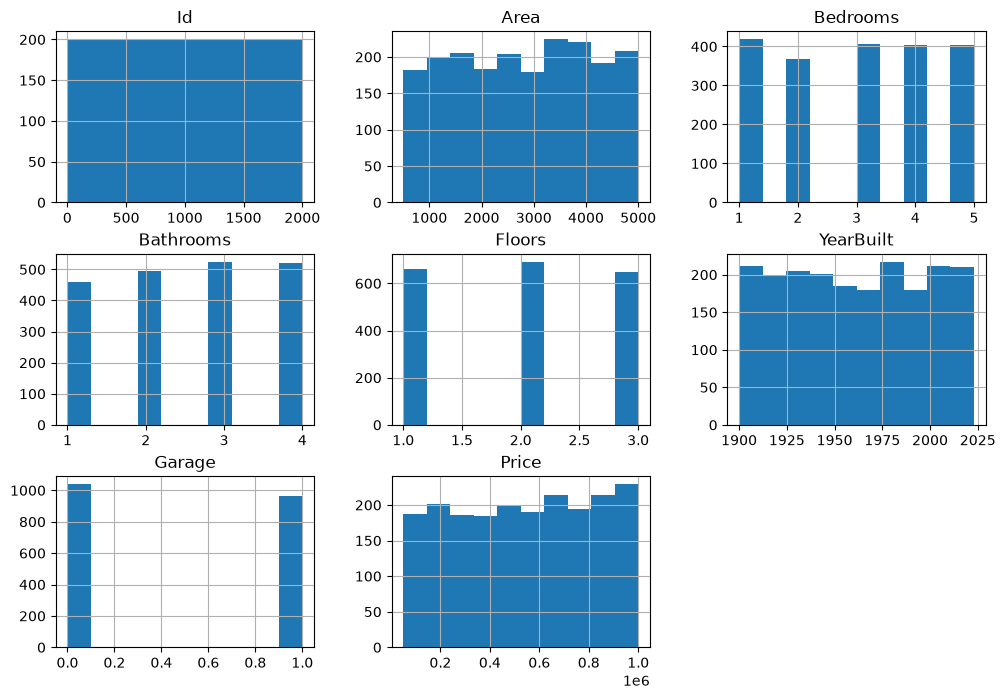

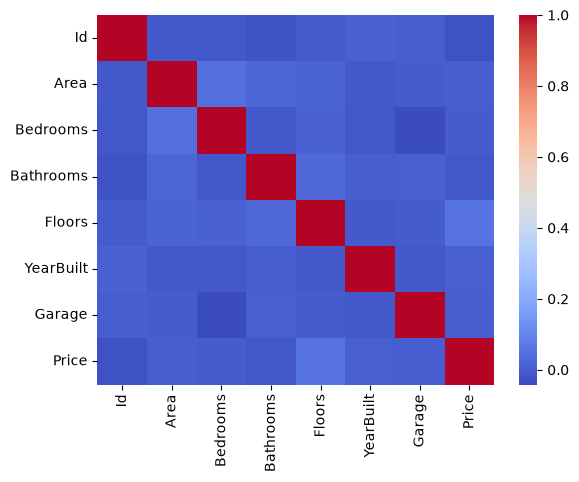

In [14]:

df1["Garage"] = df1["Garage"].map({"Yes": 1, "No": 0})
df = pd.get_dummies(df1, columns=["Condition", "Location"], dtype=int)


df1.hist(figsize=(12, 8))
plt.show()


sn.heatmap(df1.corr(numeric_only=True), cmap = "coolwarm")
plt.show()
df1.to_csv(r"C:\Users\Admin\Documents\datasets\House Price Prediction Dataset2.csv", index=False)

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error

path = r"C:\Users\Admin\Documents\datasets\House Price Prediction Dataset.csv"
df = pd.read_csv(path)
df = df.drop_duplicates()
df = df.drop(columns=["Id"])
df["Garage"] = df["Garage"].map({"Yes": 1, "No": 0})
df = pd.get_dummies(df, columns=["Condition", "Location"], dtype=int)


X = df.drop(columns=["Price"])
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
}

results = []
for name, model in models.items():
    if name == "KNN":
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

    results.append({
        "Model": name,
        "R2": round(r2_score(y_test, pred), 4),
        "MAE": round(mean_absolute_error(y_test, pred), 2),
    })
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
results.append({"Model": "Baseline (average)", "R2": 0.0, "MAE": round(baseline_mae, 2)})

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print(pd.DataFrame(results))



Training rows: 1600 | Testing rows: 400
                Model      R2        MAE
0   Linear Regression -0.0067  243241.98
1       Decision Tree -0.2879  266907.82
2                 KNN -0.2036  261569.06
3  Baseline (average)  0.0000  242480.20


                Model      R2        MAE
0   Linear Regression -0.0067  243241.98
1       Decision Tree -0.2879  266907.82
2                 KNN -0.2036  261569.06
3  Baseline (average)  0.0000  242480.20


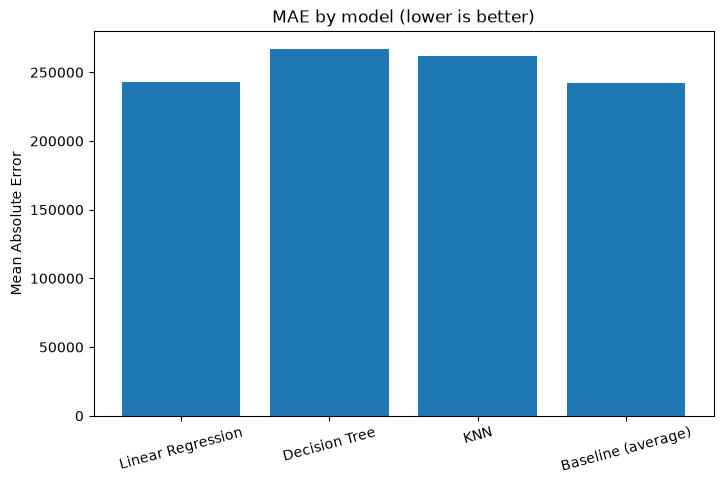

Tree R2 by depth: {2: np.float64(-0.0231), 4: np.float64(-0.0771), 6: np.float64(-0.1618), 8: np.float64(-0.2879), 10: np.float64(-0.3832), 15: np.float64(-0.6788)}
KNN R2 by k: {3: np.float64(-0.3504), 5: np.float64(-0.2036), 10: np.float64(-0.1094), 20: np.float64(-0.0335), 50: np.float64(-0.0264)}


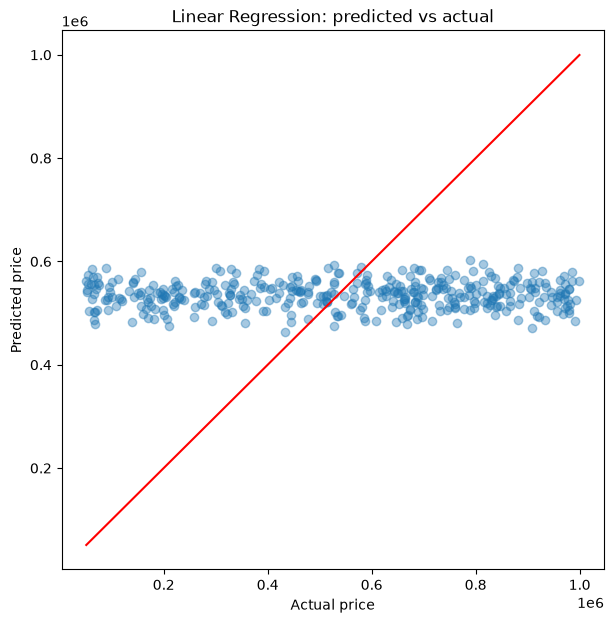

In [16]:

results_df = pd.DataFrame(results)
print(results_df)

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("MAE by model (lower is better)")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.show()

depths = [2, 4, 6, 8, 10, 15]
tree_r2 = []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    tree_r2.append(r2_score(y_test, m.predict(X_test)))


neighbors = [3, 5, 10, 20, 50]
knn_r2 = []
for k in neighbors:
    m = KNeighborsRegressor(n_neighbors=k)
    m.fit(X_train_scaled, y_train)
    knn_r2.append(r2_score(y_test, m.predict(X_test_scaled)))

print("Tree R2 by depth:", dict(zip(depths, np.round(tree_r2, 4))))
print("KNN R2 by k:", dict(zip(neighbors, np.round(knn_r2, 4))))


best_name = results_df[results_df["Model"] != "Baseline (average)"].sort_values("R2", ascending=False).iloc[0]["Model"]
best_model = models[best_name]
if best_name == "KNN":
    best_pred = best_model.predict(X_test_scaled)
else:
    best_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"{best_name}: predicted vs actual")
plt.show()

according to reports analysis , linear regression model is best for this analysis because Linear Regression performed best (R² -0.007, MAE about 243,000), but no model beat the baseline of predicting the average price. The features have almost no relationship with price, so the dataset appears to be random. Tuning the tree depth and number of neighbors didn’t help.
